# Prédiction du Ballon d'Or 2026

**Comment utiliser ce notebook :**
- Une *cellule* = un bloc. Sélectionne-la puis appuie sur **Shift + Entrée** pour l'exécuter et passer à la suivante.
- Les cellules **Markdown** (comme celle-ci) contiennent du texte, les cellules **Code** contiennent du Python.
- Exécute les cellules **dans l'ordre, de haut en bas**. Si tu as une erreur bizarre : menu **Kernel → Restart Kernel and Run All Cells**.

**Plan :** 1. Chargement · 2. Exploration (histogrammes, skewness) · 3. Boxplots · 4. Corrélations · 5. Features relatives · 6. Split · 7. Outliers (IQR) · 8. Asymétrie (log1p / Yeo-Johnson) · 9. Encodage · 10. Jeux de features · 11. Scaling · 12. Modèle · 13. Évaluation par édition · 14. Classement 2026

In [1]:
%matplotlib inline
import math
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, PowerTransformer, OneHotEncoder

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", None)
print("✅ Imports OK")

✅ Imports OK


## 1. Chargement des données
 Dans Jupyter, `__file__` n'existe pas. On cherche donc le dossier `data/raw` à partir du dossier courant du notebook.
Si le chargement échoue, change `BASE_DIR` à la main (ex : `BASE_DIR = Path(r"C:\chemin\vers\ton\projet")`).

In [2]:
# Dossier principal du projet : on cherche le dossier "data" dans le dossier courant ou ses parents
BASE_DIR = Path.cwd()
for p in [BASE_DIR, *BASE_DIR.parents]:
    if (p / "data" / "raw").exists():
        BASE_DIR = p
        break
print("BASE_DIR =", BASE_DIR)

data = pd.read_csv(BASE_DIR / "data" / "raw" / "entrainement_ballon_dor_2014_2025.csv")
data_validation = pd.read_csv(BASE_DIR / "data" / "raw" / "candidats_ballon_dor_2026.csv")

print("Shape :", data.shape)
print("\nColonnes :", data.columns.tolist())

BASE_DIR = C:\Users\Administrateur\mlops-ballon-dor
Shape : (311, 21)

Colonnes : ['edition', 'joueur', 'poste', 'couverture_stats_club', 'matchs_club_couverts', 'minutes_club_couvertes', 'buts_club_couverts', 'passes_club_couvertes', 'buts_par_90_club', 'passes_par_90_club', 'matchs_ucl', 'minutes_ucl', 'buts_ucl', 'passes_ucl', 'club_saison_champion_ucl', 'club_saison_champion_top5', 'selection_championne_cdm', 'selection_championne_euro_ou_copa', 'meilleur_joueur_ucl', 'meilleur_joueur_selection_majeure', 'gagnant_reel']


### 1.1 Aperçu des données

In [3]:
data.head()

,edition,joueur,poste,couverture_stats_club,matchs_club_couverts,minutes_club_couvertes,buts_club_couverts,passes_club_couvertes,buts_par_90_club,passes_par_90_club,matchs_ucl,minutes_ucl,buts_ucl,passes_ucl,club_saison_champion_ucl,club_saison_champion_top5,selection_championne_cdm,selection_championne_euro_ou_copa,meilleur_joueur_ucl,meilleur_joueur_selection_majeure,gagnant_reel
0,2014,Andrés Iniesta,Milieu,transfermarkt_top5_CDR_CIT_DFB_FAC_CL_EL,50,3588,3,13,0.075251,0.326087,9,779,0,3,0,0,0,0,0,0,0
1,2014,Arjen Robben,Attaquant,transfermarkt_top5_CDR_CIT_DFB_FAC_CL_EL,43,2939,19,17,0.581831,0.520585,10,877,4,6,0,1,0,0,0,0,0
2,2014,Bastian Schweinsteiger,Milieu,transfermarkt_top5_CDR_CIT_DFB_FAC_CL_EL,35,2648,8,5,0.271903,0.169940,8,588,3,0,0,1,1,0,0,0,0
3,2014,Cristiano Ronaldo,Attaquant,transfermarkt_top5_CDR_CIT_DFB_FAC_CL_EL,47,4030,51,17,1.138958,0.379653,11,993,17,5,1,0,0,0,1,0,1
4,2014,Diego Costa,Attaquant,transfermarkt_top5_CDR_CIT_DFB_FAC_CL_EL,50,4005,36,4,0.808989,0.089888,9,579,8,1,0,1,0,0,0,0,0


In [4]:
print("=== Types de données ===")
print(data.dtypes)

=== Types de données ===
edition                                int64
joueur                                   str
poste                                    str
couverture_stats_club                    str
matchs_club_couverts                   int64
minutes_club_couvertes                 int64
buts_club_couverts                     int64
passes_club_couvertes                  int64
buts_par_90_club                     float64
passes_par_90_club                   float64
matchs_ucl                             int64
minutes_ucl                            int64
buts_ucl                               int64
passes_ucl                             int64
club_saison_champion_ucl               int64
club_saison_champion_top5              int64
selection_championne_cdm               int64
selection_championne_euro_ou_copa      int64
meilleur_joueur_ucl                    int64
meilleur_joueur_selection_majeure      int64
gagnant_reel                           int64
dtype: object


In [5]:
print("=== Description des données ===")
data.describe(include="all").T

=== Description des données ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edition,311.0,NaN,NaN,NaN,2019.707395,3.527941,2014.0,2017.0,2019.0,2023.0,2025.0
joueur,311,148,Cristiano Ronaldo,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
poste,311,4,Attaquant,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
couverture_stats_club,311,5,transfermarkt_top5_CDR_CIT_DFB_FAC_CL_EL,186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
matchs_club_couverts,311.0,NaN,NaN,NaN,43.893891,8.139014,7.0,40.0,45.0,49.0,57.0
minutes_club_couvertes,311.0,NaN,NaN,NaN,3475.170418,729.901094,571.0,3148.0,3556.0,3958.0,5061.0
buts_club_couverts,311.0,NaN,NaN,NaN,16.85209,14.191683,0.0,4.0,14.0,27.0,59.0
passes_club_couvertes,311.0,NaN,NaN,NaN,8.771704,6.427961,0.0,3.0,8.0,13.0,31.0
buts_par_90_club,311.0,NaN,NaN,NaN,0.440498,0.3484,0.0,0.107851,0.407767,0.69795,1.482036
passes_par_90_club,311.0,NaN,NaN,NaN,0.227776,0.156689,0.0,0.0902,0.232408,0.332727,0.673188


### 1.2 Distribution de la cible `gagnant_reel`

Distribution gagnant_reel :
gagnant_reel
0    0.965
1    0.035
Name: proportion, dtype: float64


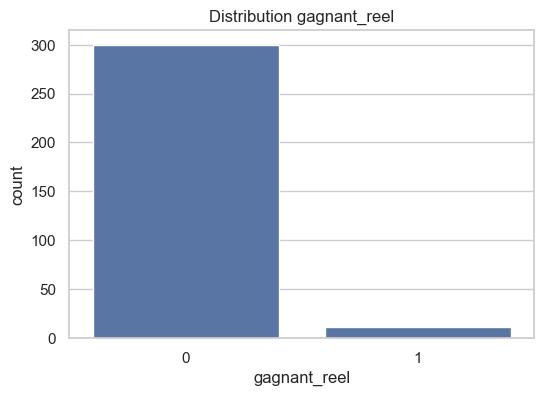


Nombre de gagnants par édition :
edition
2014    1
2015    1
2016    1
2017    1
2018    1
2019    1
2021    1
2022    1
2023    1
2024    1
2025    1
Name: gagnant_reel, dtype: int64


In [6]:
print("Distribution gagnant_reel :")
print(data["gagnant_reel"].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=data, x="gagnant_reel", ax=ax)
ax.set_title("Distribution gagnant_reel")
plt.show()

print("\nNombre de gagnants par édition :")
print(data.groupby("edition")["gagnant_reel"].sum())

## 2. Exploration : histogrammes et skewness
On sépare d'abord les variables **binaires (0/1)** des variables **continues**.

In [7]:
num_cols = [
    "edition", "matchs_club_couverts", "minutes_club_couvertes", "buts_club_couverts",
    "passes_club_couvertes", "buts_par_90_club", "passes_par_90_club",
    "matchs_ucl", "minutes_ucl", "buts_ucl", "passes_ucl",
    "club_saison_champion_ucl", "club_saison_champion_top5",
    "selection_championne_cdm", "selection_championne_euro_ou_copa",
    "meilleur_joueur_ucl", "meilleur_joueur_selection_majeure",
]

binary_cols = [
    col for col in num_cols
    if set(data[col].dropna().unique()).issubset({0, 1})
    and len(data[col].dropna().unique()) <= 2
]
continuous_cols = [col for col in num_cols if col not in binary_cols]

print("Binaires  :", binary_cols)
print("Continues :", continuous_cols)

Binaires  : ['club_saison_champion_ucl', 'club_saison_champion_top5', 'selection_championne_cdm', 'selection_championne_euro_ou_copa', 'meilleur_joueur_ucl', 'meilleur_joueur_selection_majeure']
Continues : ['edition', 'matchs_club_couverts', 'minutes_club_couvertes', 'buts_club_couverts', 'passes_club_couvertes', 'buts_par_90_club', 'passes_par_90_club', 'matchs_ucl', 'minutes_ucl', 'buts_ucl', 'passes_ucl']


### 2.1 Tableau des skewness (asymétrie)
Skewness proche de 0 = symétrique ; > 1 = fortement asymétrique à droite.

In [8]:
skew_table = (data[continuous_cols].skew()
              .sort_values(ascending=False)
              .rename("skewness").to_frame())
skew_table

,skewness
buts_ucl,1.314108
passes_ucl,1.228295
buts_club_couverts,0.679390
passes_club_couvertes,0.571864
buts_par_90_club,0.452538
passes_par_90_club,0.318297
edition,-0.028561
minutes_ucl,-0.634636
matchs_ucl,-0.831440
minutes_club_couvertes,-1.366711


In [9]:
def interpreter_skew(s):
    if abs(s) < 0.5:
        return "Symétrique"
    elif abs(s) < 1:
        return "Asymétrie modérée"
    else:
        return "Asymétrie FORTE"

skew_table = pd.DataFrame({"skewness": data[continuous_cols].skew()})
skew_table["sens"] = np.where(skew_table["skewness"] > 0, "droite", "gauche")
skew_table["interprétation"] = skew_table["skewness"].apply(interpreter_skew)
skew_table = skew_table.sort_values("skewness", key=abs, ascending=False)

skew_table.round(2)

,skewness,sens,interprétation
matchs_club_couverts,-2.01,gauche,Asymétrie FORTE
minutes_club_couvertes,-1.37,gauche,Asymétrie FORTE
buts_ucl,1.31,droite,Asymétrie FORTE
passes_ucl,1.23,droite,Asymétrie FORTE
matchs_ucl,-0.83,gauche,Asymétrie modérée
buts_club_couverts,0.68,droite,Asymétrie modérée
minutes_ucl,-0.63,gauche,Asymétrie modérée
passes_club_couvertes,0.57,droite,Asymétrie modérée
buts_par_90_club,0.45,droite,Symétrique
passes_par_90_club,0.32,droite,Symétrique


### 2.2 Histogrammes des variables continues (3 par ligne)

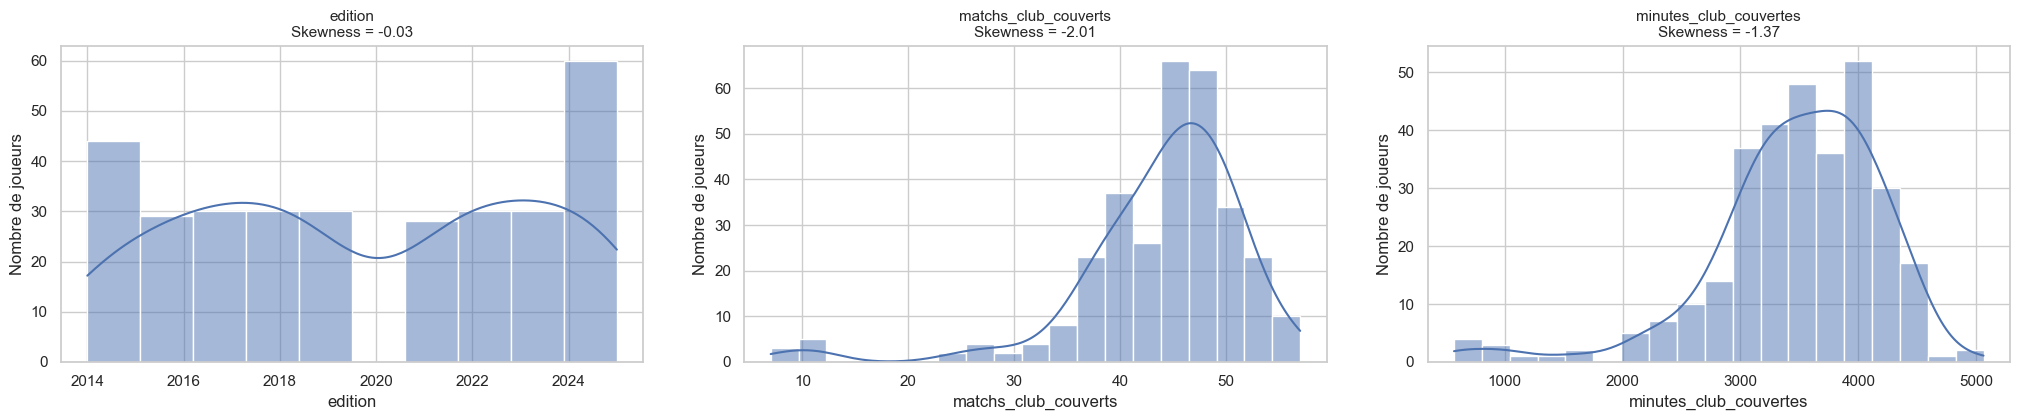

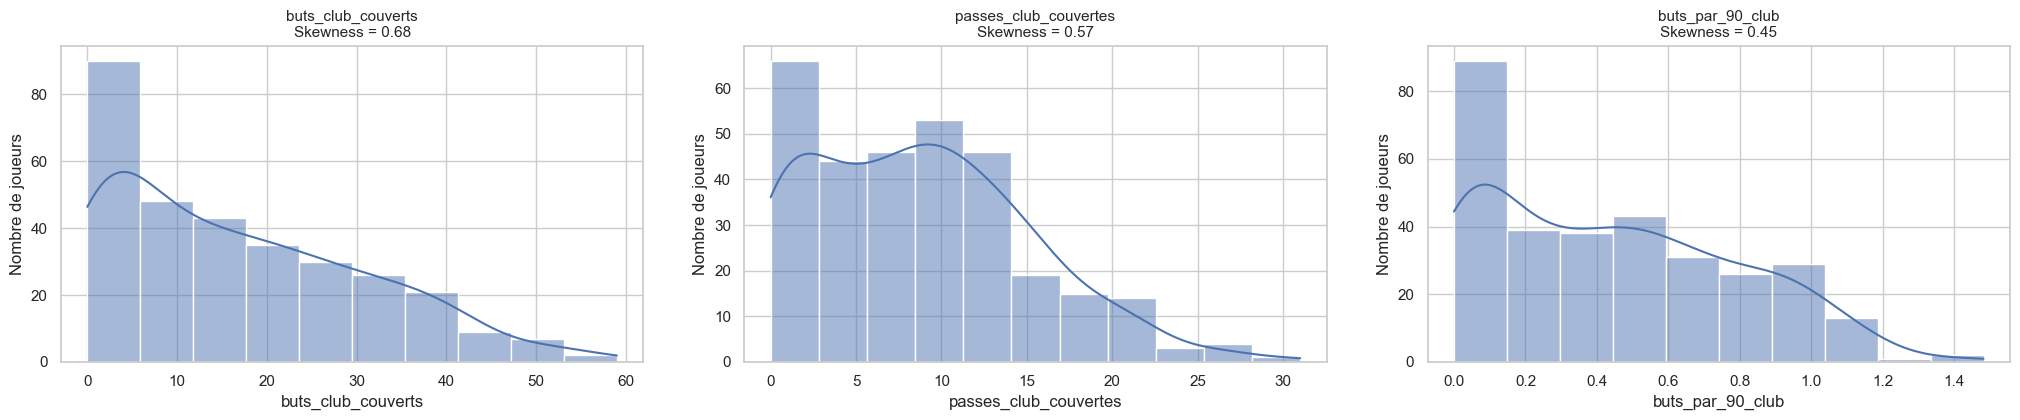

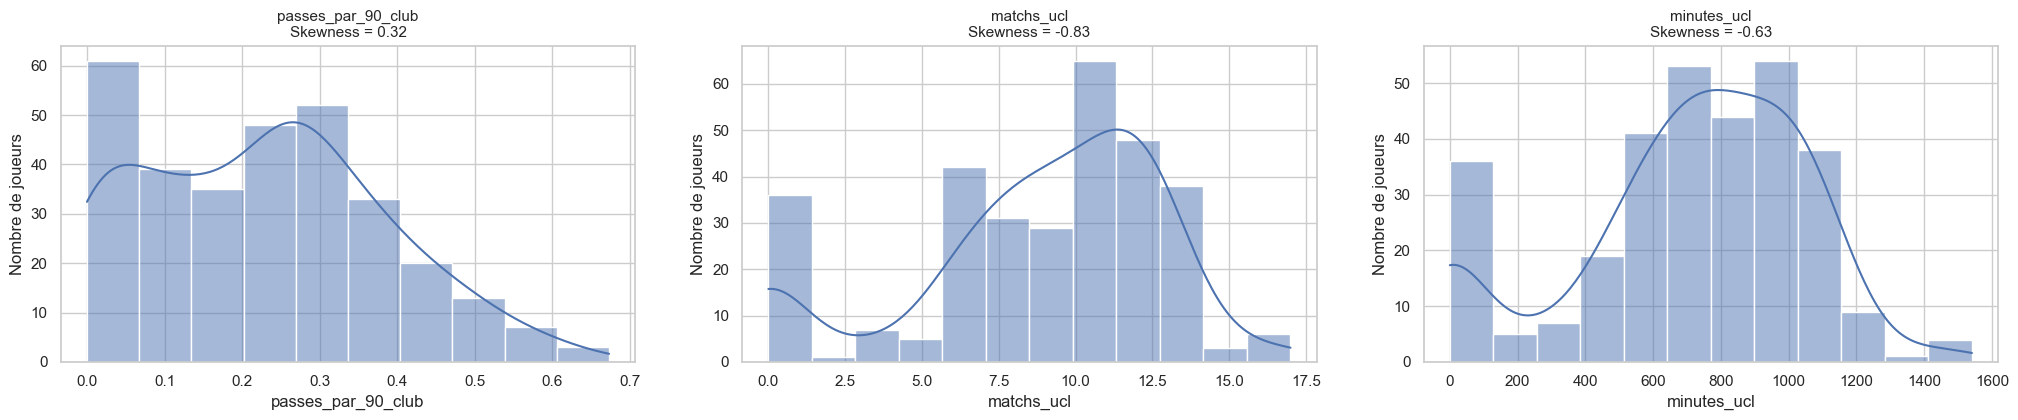

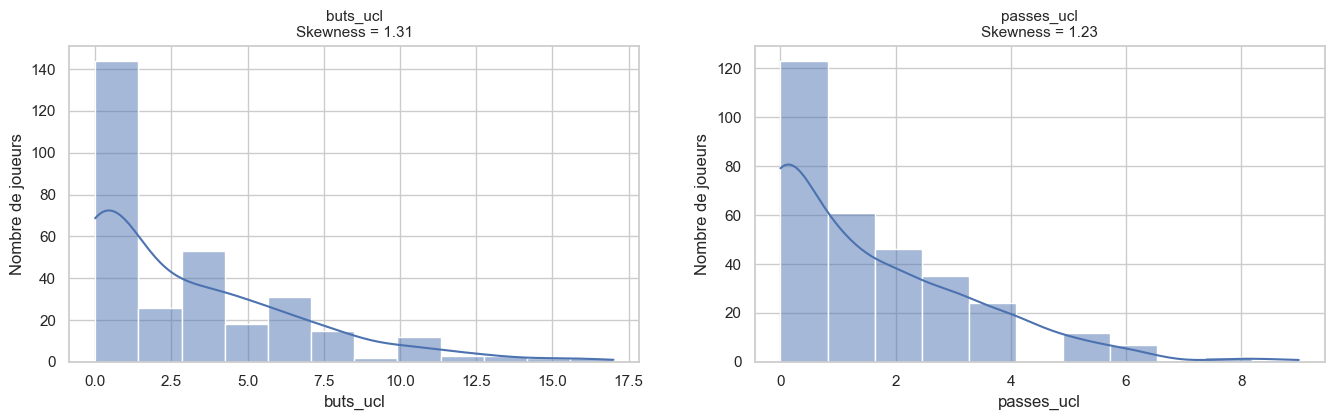

In [10]:
def afficher_histogrammes(columns, ncols=3):
    for start in range(0, len(columns), ncols):
        batch = columns[start:start + ncols]
        nrows = math.ceil(len(batch) / ncols)

        fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5 * nrows), squeeze=False)
        axes = axes.ravel()

        for i, col in enumerate(batch):
            ax = axes[i]
            values = data[col].dropna()
            sns.histplot(values, kde=len(values.unique()) > 5, ax=ax)
            ax.set_title(f"{col}\nSkewness = {values.skew():.2f}", fontsize=11)
            ax.set_xlabel(col)
            ax.set_ylabel("Nombre de joueurs")

        for j in range(len(batch), len(axes)):
            fig.delaxes(axes[j])

        plt.tight_layout(pad=3)
        plt.show()

afficher_histogrammes(continuous_cols)

### 2.3 Variables binaires (graphiques en barres)

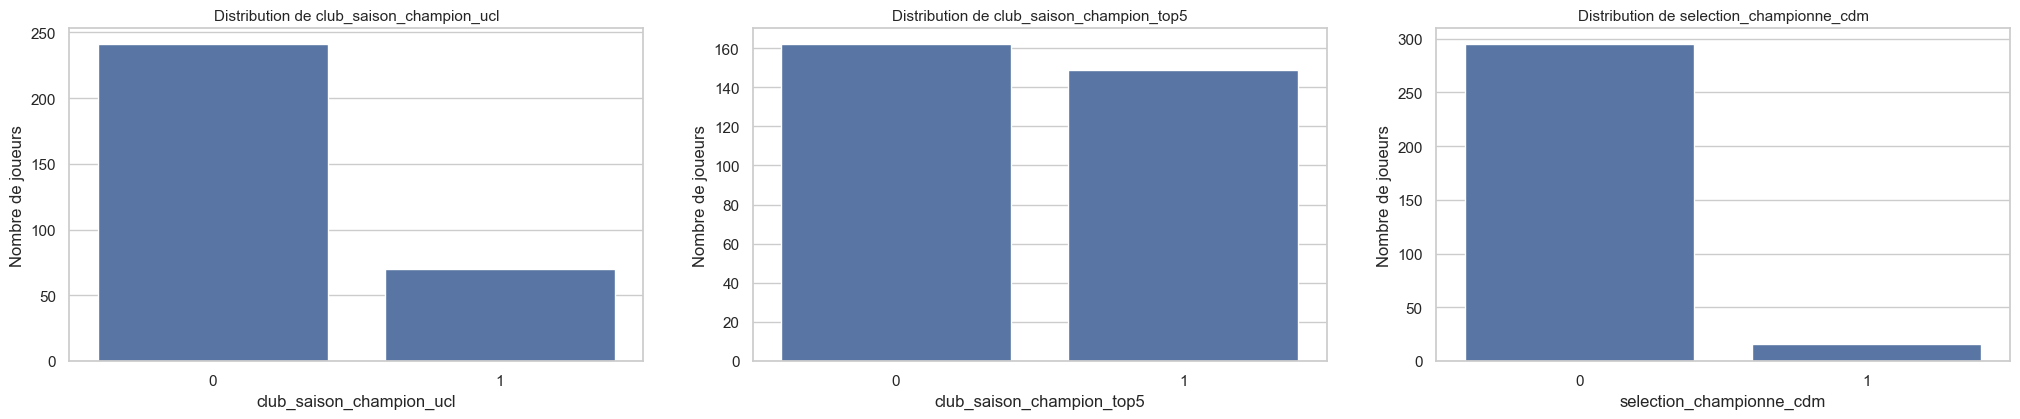

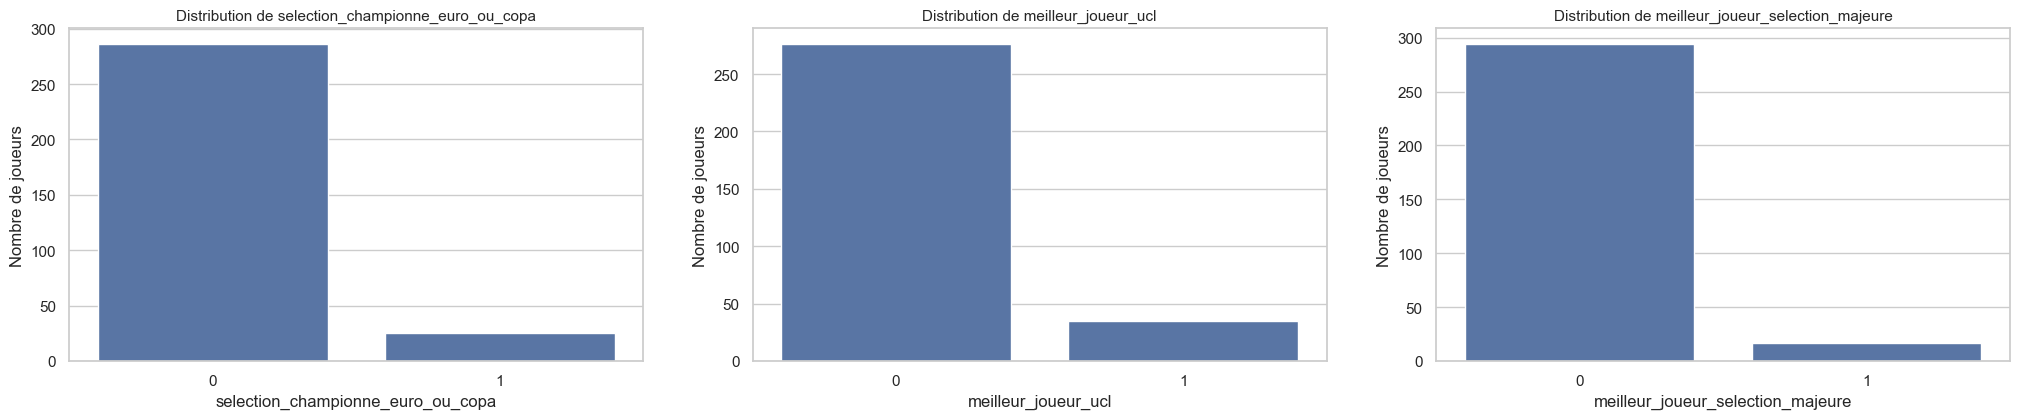

In [11]:
def afficher_variables_binaires(columns, ncols=3):
    for start in range(0, len(columns), ncols):
        batch = columns[start:start + ncols]
        nrows = math.ceil(len(batch) / ncols)

        fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5 * nrows), squeeze=False)
        axes = axes.ravel()

        for i, col in enumerate(batch):
            sns.countplot(x=data[col], ax=axes[i])
            axes[i].set_title(f"Distribution de {col}", fontsize=11)
            axes[i].set_xlabel(col)
            axes[i].set_ylabel("Nombre de joueurs")

        for j in range(len(batch), len(axes)):
            fig.delaxes(axes[j])

        plt.tight_layout(pad=3)
        plt.show()

afficher_variables_binaires(binary_cols)

## 3. Boxplots (détection des valeurs extrêmes)

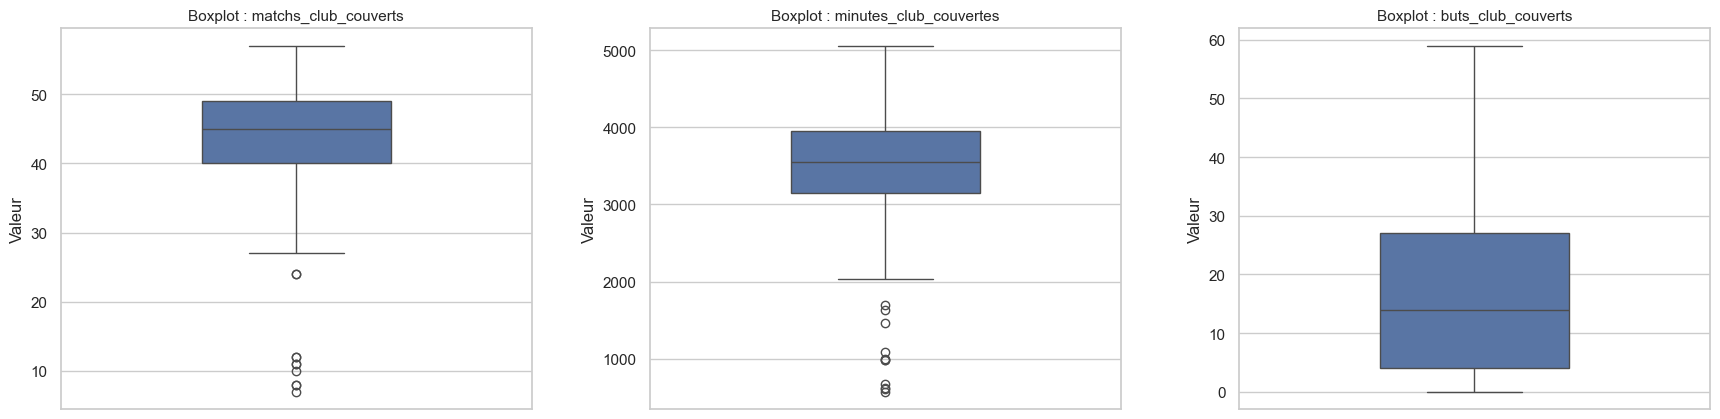

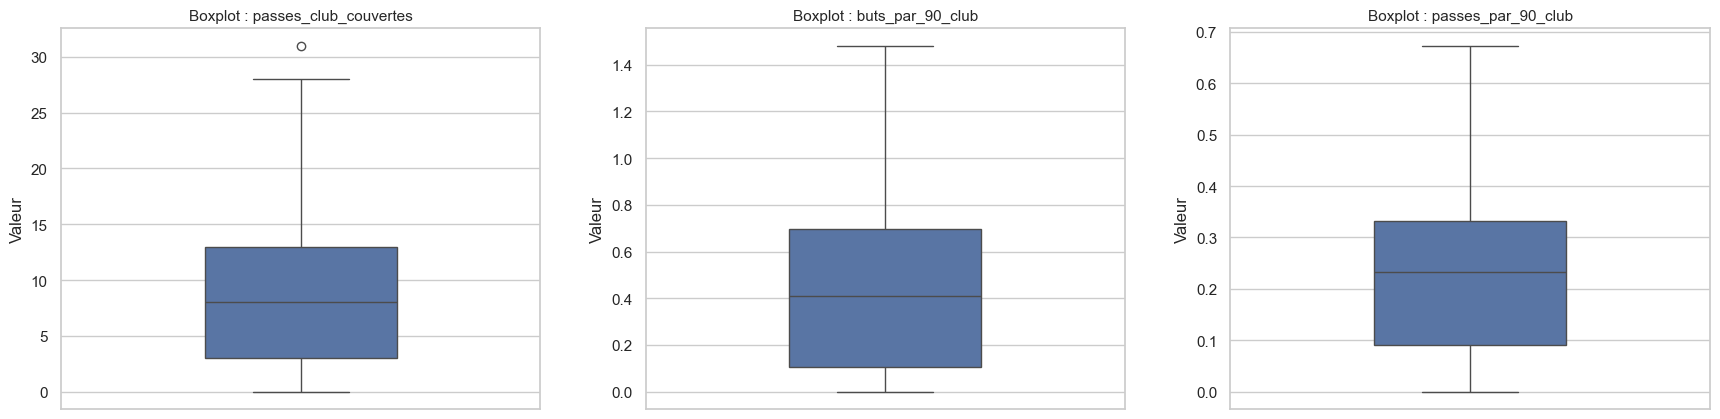

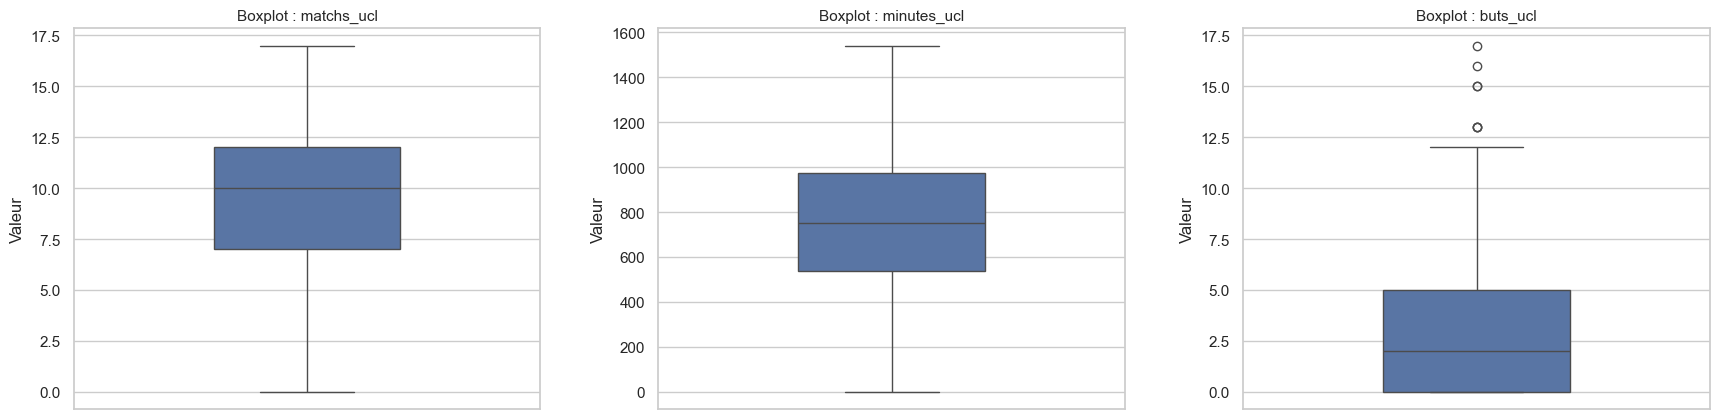

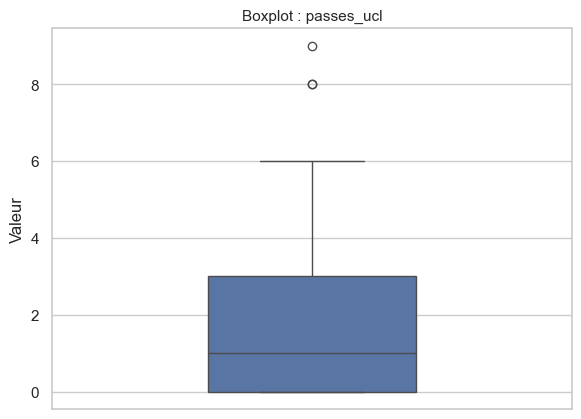

In [12]:
box_cols = [
    "matchs_club_couverts", "minutes_club_couvertes", "buts_club_couverts",
    "passes_club_couvertes", "buts_par_90_club", "passes_par_90_club",
    "matchs_ucl", "minutes_ucl", "buts_ucl", "passes_ucl",
]

ncols = 3
for start in range(0, len(box_cols), ncols):
    cols = box_cols[start:start + ncols]
    nrows = math.ceil(len(cols) / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows), squeeze=False)
    axes = axes.ravel()

    for i, col in enumerate(cols):
        sns.boxplot(y=data[col].dropna(), ax=axes[i], width=0.4)
        axes[i].set_title(f"Boxplot : {col}", fontsize=11)
        axes[i].set_ylabel("Valeur")

    for j in range(len(cols), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout(pad=3)
    plt.show()

### 3.1 Variables catégorielles

In [13]:
cat_cols = ["poste", "couverture_stats_club"]

for col in cat_cols:
    print(f"\n{'=' * 50}")
    print(f"Colonne : {col}")
    print(f"Nombre de valeurs uniques : {data[col].nunique()}")
    print("\nValeurs uniques :", data[col].dropna().unique())
    print("\nNombre d'occurrences :")
    print(data[col].value_counts(dropna=False))


Colonne : poste
Nombre de valeurs uniques : 4

Valeurs uniques : <ArrowStringArray>
['Milieu', 'Attaquant', 'Gardien', 'Defenseur']
Length: 4, dtype: str

Nombre d'occurrences :
poste
Attaquant    151
Milieu        96
Defenseur     40
Gardien       24
Name: count, dtype: int64

Colonne : couverture_stats_club
Nombre de valeurs uniques : 5

Valeurs uniques : <ArrowStringArray>
[    'transfermarkt_top5_CDR_CIT_DFB_FAC_CL_EL',
      'transfermarkt_hors_top5_CL_EL_seulement',
       'perimetre_top5_et_coupes_selectionnees',
 'hors_top5_competitions_europeennes_seulement',
              'mixte_top5_et_hors_top5_partiel']
Length: 5, dtype: str

Nombre d'occurrences :
couverture_stats_club
transfermarkt_top5_CDR_CIT_DFB_FAC_CL_EL        186
perimetre_top5_et_coupes_selectionnees          116
transfermarkt_hors_top5_CL_EL_seulement           5
hors_top5_competitions_europeennes_seulement      3
mixte_top5_et_hors_top5_partiel                   1
Name: count, dtype: int64


## 4. Corrélation des features avec la cible

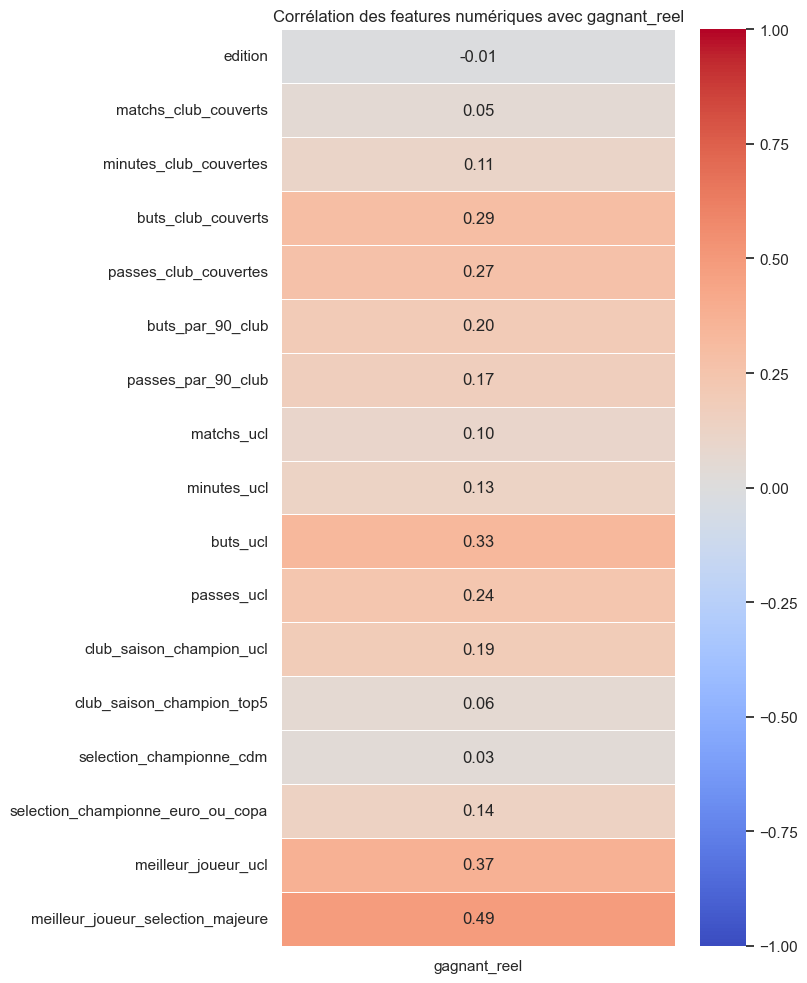

In [14]:
target = "gagnant_reel"
corr = data[num_cols + [target]].corr(numeric_only=True)

plt.figure(figsize=(8, 10))
sns.heatmap(corr[[target]].drop(index=target), annot=True, cmap="coolwarm",
            fmt=".2f", vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.title("Corrélation des features numériques avec gagnant_reel")
plt.tight_layout()
plt.show()

## 5. Features relatives à l'édition (feature engineering)
Le Ballon d'Or est une compétition entre candidats **d'une même année** : on compare chaque joueur aux autres candidats de son édition (rang en percentile, écart au meilleur). La cible n'est pas utilisée → pas de fuite de données.

In [15]:
cols_relatives_src = [
    "buts_club_couverts", "passes_club_couvertes", "buts_par_90_club", "passes_par_90_club",
    "buts_ucl", "passes_ucl", "minutes_ucl", "minutes_club_couvertes",
]

def ajouter_features_relatives(df, groupes):
    df = df.copy()
    for c in cols_relatives_src:
        g = df.groupby(groupes)[c]
        df[c + "_rk"] = g.rank(pct=True)             # rang en percentile dans l'édition
        df[c + "_gap"] = df[c] - g.transform("max")  # écart au meilleur de l'édition
    contributions = df["buts_club_couverts"] + df["passes_club_couvertes"]
    df["ga_club_rk"] = contributions.groupby(groupes).rank(pct=True)
    df["titres_total"] = (
        df["club_saison_champion_ucl"] + df["club_saison_champion_top5"]
        + df["selection_championne_cdm"] + df["selection_championne_euro_ou_copa"]
    )
    return df

data = ajouter_features_relatives(data, data["edition"])
data_validation = ajouter_features_relatives(
    data_validation, pd.Series(2026, index=data_validation.index)
)

# ga_club_rk finit déjà par "_rk" : on ne l'ajoute donc pas à la main
cols_rk = [c for c in data.columns if c.endswith("_rk")]
cols_gap = [c for c in data.columns if c.endswith("_gap")]
nouvelles_cols = cols_rk + cols_gap + ["titres_total"]

print("✅ Features relatives créées")
print(f"\nColonnes _rk  ({len(cols_rk)}) :", cols_rk)
print(f"\nColonnes _gap ({len(cols_gap)}) :", cols_gap)
print("\nColonne spéciale : titres_total")
print(f"\nTotal de nouvelles colonnes : {len(nouvelles_cols)}")

✅ Features relatives créées

Colonnes _rk  (9) : ['buts_club_couverts_rk', 'passes_club_couvertes_rk', 'buts_par_90_club_rk', 'passes_par_90_club_rk', 'buts_ucl_rk', 'passes_ucl_rk', 'minutes_ucl_rk', 'minutes_club_couvertes_rk', 'ga_club_rk']

Colonnes _gap (8) : ['buts_club_couverts_gap', 'passes_club_couvertes_gap', 'buts_par_90_club_gap', 'passes_par_90_club_gap', 'buts_ucl_gap', 'passes_ucl_gap', 'minutes_ucl_gap', 'minutes_club_couvertes_gap']

Colonne spéciale : titres_total

Total de nouvelles colonnes : 18


## 6. Séparation des données (X / y, train / test)

In [16]:
noms_validation = data_validation["joueur"].copy()
X_validation = data_validation.drop(columns=["joueur", "gagnant_reel"], errors="ignore")

X = data.drop(columns=["joueur", "gagnant_reel"])
y = data["gagnant_reel"]

# Mêmes colonnes que X pour les candidats 2026
X_validation = X_validation.reindex(columns=X.columns)
print("Forme de X_validation :", X_validation.shape)
print("Colonnes manquantes dans le fichier 2026 :", X.columns.difference(data_validation.columns).tolist())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain : {X_train.shape[0]} | Test : {X_test.shape[0]}")
print(f"Gagnants train : {y_train.sum()} / {len(y_train)}")
print(f"Gagnants test  : {y_test.sum()} / {len(y_test)}")
print(f"Proportion train : {y_train.mean():.3f} | test : {y_test.mean():.3f}")

Forme de X_validation : (28, 37)
Colonnes manquantes dans le fichier 2026 : []

Train : 248 | Test : 63
Gagnants train : 9 / 248
Gagnants test  : 2 / 63
Proportion train : 0.036 | test : 0.032


## 7. Gestion des valeurs extrêmes (clipping IQR)
Les limites sont calculées sur le **train seulement**, puis appliquées au test et à 2026.

In [17]:
def iqr_clip(series, factor=1.5):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - factor * IQR, Q3 + factor * IQR
    return series.clip(lower, upper), lower, upper

cols_iqr = ["matchs_club_couverts", "minutes_club_couvertes", "buts_ucl"]
iqr_limits = {}

for col in cols_iqr:
    X_train[col], low, up = iqr_clip(X_train[col])
    iqr_limits[col] = (low, up)
    X_test[col] = X_test[col].clip(lower=low, upper=up)
    X_validation[col] = X_validation[col].clip(lower=low, upper=up)
    print(f"{col} : clipping entre {low:.1f} et {up:.1f}")

# Sauvegarde AVANT les transformations
X_train_base, X_test_base = X_train.copy(), X_test.copy()
y_train_base, y_test_base = y_train.copy(), y_test.copy()

matchs_club_couverts : clipping entre 28.4 et 61.4
minutes_club_couvertes : clipping entre 1900.2 et 5230.2
buts_ucl : clipping entre -7.5 et 12.5


## 8. Asymétrie : log1p et Yeo-Johnson

In [18]:
cols_log = ["buts_ucl", "passes_ucl"]

for col in cols_log:
    X_train[col + "_log1p"] = np.log1p(X_train[col])
    X_test[col + "_log1p"] = np.log1p(X_test[col])
    X_validation[col + "_log1p"] = np.log1p(X_validation[col])
    print(f"{col} -> skew avant : {X_train[col].skew():.3f} | après : {X_train[col + '_log1p'].skew():.3f}")

X_train = X_train.drop(columns=cols_log)
X_test = X_test.drop(columns=cols_log)
X_validation = X_validation.drop(columns=cols_log)
#____________________________________________________
col = "matchs_club_couverts"
yeo = PowerTransformer(method="yeo-johnson", standardize=False)

X_train[col + "_yeo"] = yeo.fit_transform(X_train[[col]]).ravel()   # fit sur le train seulement
X_test[col + "_yeo"] = yeo.transform(X_test[[col]]).ravel()
X_validation[col + "_yeo"] = yeo.transform(X_validation[[col]]).ravel()

print(" __Yeo-Johnson terminé__")
print("Skew avant :", round(X_train[col].skew(), 3))
print("Skew après :", round(X_train[col + "_yeo"].skew(), 3))

buts_ucl -> skew avant : 1.177 | après : 0.133
passes_ucl -> skew avant : 1.252 | après : 0.239
 __Yeo-Johnson terminé__
Skew avant : -0.653
Skew après : -0.062


## 9. Encodage du poste (One-Hot)
On n'encode que `poste` : `couverture_stats_club` décrit la source des stats, pas le joueur.

In [19]:
ohe_cols = ["poste"]
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="first")
noms_ohe = ohe.fit(X_train[ohe_cols]).get_feature_names_out(ohe_cols)

def encoder(Xdf):
    enc = pd.DataFrame(ohe.transform(Xdf[ohe_cols]), columns=noms_ohe, index=Xdf.index)
    return pd.concat([Xdf.drop(columns=ohe_cols), enc], axis=1)

X_train = encoder(X_train)
X_test = encoder(X_test)
X_validation = encoder(X_validation)

ohe_feature_cols = list(noms_ohe)
print("One-Hot features créées :", ohe_feature_cols)

One-Hot features créées : ['poste_Defenseur', 'poste_Gardien', 'poste_Milieu']


## 10. Regroupement des données et jeux de features

In [20]:
X_all = pd.concat([X_train, X_test])
y_all = pd.concat([y_train, y_test])
groupes_all = data.loc[X_all.index, "edition"]

print(f"Données regroupées : {X_all.shape[0]} joueurs | {int(y_all.sum())} gagnants | {groupes_all.nunique()} éditions")
print("Valeurs manquantes :", int(X_all.isnull().sum().sum()))

resume_editions = (pd.DataFrame({"edition": groupes_all, "gagnant": y_all})
                   .groupby("edition")["gagnant"].agg(candidats="count", gagnants="sum"))
resume_editions
# Colonnes BRUTES (valeurs d'origine du CSV) pour la vraie baseline
cols_brutes = [
    "matchs_club_couverts", "minutes_club_couvertes", "buts_club_couverts",
    "passes_club_couvertes", "buts_par_90_club", "passes_par_90_club",
    "matchs_ucl", "minutes_ucl", "buts_ucl", "passes_ucl",
]
for c in cols_brutes:
    X_all[c + "_brut"] = data.loc[X_all.index, c]
    X_validation[c + "_brut"] = data_validation.loc[X_validation.index, c]

brut_cols = [c + "_brut" for c in cols_brutes]

raw_num_cols = [
    "minutes_club_couvertes", "buts_club_couverts", "passes_club_couvertes",
    "buts_par_90_club", "passes_par_90_club", "matchs_ucl", "minutes_ucl",
]
transformed_cols = ["matchs_club_couverts_yeo", "buts_ucl_log1p", "passes_ucl_log1p"]
binary_feature_cols = [
    "club_saison_champion_ucl", "club_saison_champion_top5",
    "selection_championne_cdm", "selection_championne_euro_ou_copa",
    "meilleur_joueur_ucl", "meilleur_joueur_selection_majeure",
]
relative_cols = ([c + "_rk" for c in cols_relatives_src]
                 + [c + "_gap" for c in cols_relatives_src]
                 + ["ga_club_rk", "titres_total"])
ohe_poste_cols = [c for c in ohe_feature_cols if c.startswith("poste_")]

jeux_features = {
    "Baseline brute": brut_cols + binary_feature_cols + ohe_poste_cols,
    "Prétraité": raw_num_cols + transformed_cols + binary_feature_cols + ohe_poste_cols,
    "Prétraité + FE": (raw_num_cols + transformed_cols + relative_cols
                       + binary_feature_cols + ohe_poste_cols),
}
cols_continues = set(raw_num_cols + transformed_cols + relative_cols + brut_cols)

for nom, cols in jeux_features.items():
    manquantes = [c for c in cols if c not in X_all.columns]
    if manquantes:
        raise ValueError(f"{nom} : colonnes absentes {manquantes}")
    print(f"{nom:<22}: {len(cols)} features")

Données regroupées : 311 joueurs | 11 gagnants | 11 éditions
Valeurs manquantes : 0
Baseline brute        : 19 features
Prétraité             : 19 features
Prétraité + FE        : 37 features


## 11. Scaling (RobustScaler) : démonstration
Le scaling ramène la médiane à 0 et l'IQR à 1. Les colonnes 0/1 ne sont pas scalées.

In [21]:
cols_a_scaler = [c for c in jeux_features["Prétraité + FE"] if c in cols_continues]
scaler = RobustScaler()
X_all_scaled_demo = pd.DataFrame(scaler.fit_transform(X_all[cols_a_scaler]),
                                 columns=cols_a_scaler, index=X_all.index)

def iqr(df):
    return df.quantile(0.75) - df.quantile(0.25)

tableau_scaling = pd.DataFrame({
    "mediane_avant": X_all[cols_a_scaler].median(),
    "IQR_avant": iqr(X_all[cols_a_scaler]),
    "mediane_apres": X_all_scaled_demo.median(),
    "IQR_apres": iqr(X_all_scaled_demo),
})
print("✅ Scaling terminé (RobustScaler)")
tableau_scaling.round(3)

✅ Scaling terminé (RobustScaler)


,mediane_avant,IQR_avant,mediane_apres,IQR_apres
minutes_club_couvertes,3556.000,810.000,0.0,1.0
buts_club_couverts,14.000,23.000,0.0,1.0
passes_club_couvertes,8.000,10.000,0.0,1.0
buts_par_90_club,0.408,0.590,0.0,1.0
passes_par_90_club,0.232,0.243,0.0,1.0
matchs_ucl,10.000,5.000,0.0,1.0
minutes_ucl,751.000,435.500,0.0,1.0
matchs_club_couverts_yeo,8229.030,4127.593,0.0,1.0
buts_ucl_log1p,1.099,1.792,0.0,1.0
passes_ucl_log1p,0.693,1.386,0.0,1.0


## 12. Modèle : régression logistique dans un Pipeline
Le scaler est refait **dans** le Pipeline, à chaque pli, sur les seules éditions d'entraînement.

In [22]:
def construire_modele(colonnes, class_weight=None, C=0.3):
    continues = [c for c in colonnes if c in cols_continues]
    prep = ColumnTransformer(
        [("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                           ("sc", RobustScaler())]), continues)],
        remainder="passthrough",
    )
    return Pipeline([
        ("prep", prep),
        ("lr", LogisticRegression(C=C, class_weight=class_weight, max_iter=3000, random_state=42)),
    ])
print("✅ Fonction construire_modele définie")

✅ Fonction construire_modele définie


## 13. Évaluation par édition (Leave-One-Edition-Out)
On cache une édition, on entraîne sur les autres, et on regarde le rang donné au vrai gagnant.

In [23]:
def evaluer_par_edition(colonnes, class_weight):
    Xc = X_all[colonnes]
    modele = construire_modele(colonnes, class_weight)
    proba = pd.Series(index=Xc.index, dtype=float)
    for tr, va in LeaveOneGroupOut().split(Xc, y_all, groupes_all):
        m = clone(modele).fit(Xc.iloc[tr], y_all.iloc[tr])
        proba.iloc[va] = m.predict_proba(Xc.iloc[va])[:, 1]

    part = proba / proba.groupby(groupes_all).transform("sum")
    lignes = []
    for ed, idx in groupes_all.groupby(groupes_all).groups.items():
        gagnant = idx[y_all.loc[idx].values == 1]
        if len(gagnant) == 0:
            continue
        g = gagnant[0]
        lignes.append({
            "edition": ed,
            "gagnant": data.loc[g, "joueur"],
            "rang": int((proba.loc[idx] >= proba.loc[g]).sum()),
            "part_gagnant": part.loc[g],
        })
    det = pd.DataFrame(lignes).set_index("edition")

    # 1 annonce (le 1er) et 1 vrai gagnant par édition : Precision = Recall = F1 = Top-1
    y_pred = pd.Series(0, index=Xc.index)
    for ed, idx in groupes_all.groupby(groupes_all).groups.items():
        y_pred.loc[proba.loc[idx].idxmax()] = 1
    y_vrai = y_all.loc[Xc.index]

    resume = {
        "Top-1": (det["rang"] == 1).mean(),
        "Top-3": (det["rang"] <= 3).mean(),
        "Rang moyen": det["rang"].mean(),
        "Part moy. du gagnant (%)": 100 * det["part_gagnant"].mean(),
        "Precision": precision_score(y_vrai, y_pred, zero_division=0),
        "Recall": recall_score(y_vrai, y_pred, zero_division=0),
        "F1-score": f1_score(y_vrai, y_pred, zero_division=0),
    }
    return resume, det

resultats, details = {}, {}
for nom_jeu, cols in jeux_features.items():
    for cw in (None, "balanced"):
        nom = f"{nom_jeu} | class_weight={cw}"
        resultats[nom], details[nom] = evaluer_par_edition(cols, cw)

df_res = pd.DataFrame(resultats).T.sort_values(
    ["Rang moyen", "Part moy. du gagnant (%)"], ascending=[True, False])
print("===== BASELINE BRUTE vs PRÉTRAITÉ vs PRÉTRAITÉ + FE =====")
df_res.round(3)

===== BASELINE BRUTE vs PRÉTRAITÉ vs PRÉTRAITÉ + FE =====


,Top-1,Top-3,Rang moyen,Part moy. du gagnant (%),Precision,Recall,F1-score
Baseline brute | class_weight=balanced,0.727,1.000,1.273,22.920,0.727,0.727,0.727
Prétraité | class_weight=balanced,0.727,1.000,1.273,22.058,0.727,0.727,0.727
Prétraité + FE | class_weight=balanced,0.727,0.909,1.545,29.161,0.727,0.727,0.727
Prétraité | class_weight=None,0.636,1.000,1.636,25.602,0.636,0.636,0.636
Prétraité + FE | class_weight=None,0.727,0.909,1.727,36.610,0.727,0.727,0.727
Baseline brute | class_weight=None,0.636,0.909,1.818,27.957,0.636,0.636,0.636


In [24]:
meilleur_auto = df_res.index[0]
print(f"Première ligne du tableau (tri automatique) : {meilleur_auto}")

# Choix manuel : Prétraité et Baseline brute sont à égalité (Top-1, Top-3, rang moyen).
# On retient Prétraité pour sa robustesse aux valeurs extrêmes sur les nouvelles données.
meilleur = "Prétraité | class_weight=balanced"
print(f"Configuration retenue : {meilleur}")
print("\nRang du vrai gagnant par édition (1 = trouvé) :")
details[meilleur].round(3)

Première ligne du tableau (tri automatique) : Baseline brute | class_weight=balanced
Configuration retenue : Prétraité | class_weight=balanced

Rang du vrai gagnant par édition (1 = trouvé) :


,gagnant,rang,part_gagnant
edition,,,
2014,Cristiano Ronaldo,1,0.229
2015,Lionel Messi,1,0.243
2016,Cristiano Ronaldo,1,0.212
2017,Cristiano Ronaldo,2,0.154
2018,Luka Modrić,1,0.163
2019,Lionel Messi,1,0.299
2021,Lionel Messi,1,0.346
2022,Karim Benzema,1,0.248
2023,Lionel Messi,2,0.152


## 14. Modèle final et classement 2026

In [25]:
nom_jeu, cw_txt = meilleur.split(" | class_weight=")
cw = None if cw_txt == "None" else cw_txt
colonnes_finales = jeux_features[nom_jeu]

print("===== MODÈLE FINAL UTILISÉ POUR 2026 =====")
print(f"Jeu de variables    : {nom_jeu}")
print(f"class_weight        : {cw}")
print(f"Nombre de variables : {len(colonnes_finales)}")
print("Variables :", colonnes_finales)

modele_final = construire_modele(colonnes_finales, cw).fit(X_all[colonnes_finales], y_all)
proba_2026 = modele_final.predict_proba(X_validation[colonnes_finales])[:, 1]

classement = pd.DataFrame({"joueur": noms_validation.values, "proba_brute": proba_2026})
classement["chance_%"] = 100 * classement["proba_brute"] / classement["proba_brute"].sum()
classement = classement.sort_values("proba_brute", ascending=False).reset_index(drop=True)
classement["rang"] = classement.index + 1

===== MODÈLE FINAL UTILISÉ POUR 2026 =====
Jeu de variables    : Prétraité
class_weight        : balanced
Nombre de variables : 19
Variables : ['minutes_club_couvertes', 'buts_club_couverts', 'passes_club_couvertes', 'buts_par_90_club', 'passes_par_90_club', 'matchs_ucl', 'minutes_ucl', 'matchs_club_couverts_yeo', 'buts_ucl_log1p', 'passes_ucl_log1p', 'club_saison_champion_ucl', 'club_saison_champion_top5', 'selection_championne_cdm', 'selection_championne_euro_ou_copa', 'meilleur_joueur_ucl', 'meilleur_joueur_selection_majeure', 'poste_Defenseur', 'poste_Gardien', 'poste_Milieu']


In [26]:
print("===== TOP 10 CANDIDATS 2026 =====")
print("TOP 3 annoncé :", ", ".join(classement["joueur"].head(3)))
classement.head(10)[["rang", "joueur", "chance_%"]].round(1)

===== TOP 10 CANDIDATS 2026 =====
TOP 3 annoncé : Lamine Yamal, Kylian Mbappé, Ousmane Dembélé


,rang,joueur,chance_%
0,1,Lamine Yamal,17.7
1,2,Kylian Mbappé,15.9
2,3,Ousmane Dembélé,11.8
3,4,Khvicha Kvaratskhelia,10.9
4,5,Michael Olise,9.3
5,6,Harry Kane,6.6
6,7,Erling Haaland,4.0
7,8,Luis Díaz,3.5
8,9,Achraf Hakimi,3.2
9,10,Vitinha,3.2


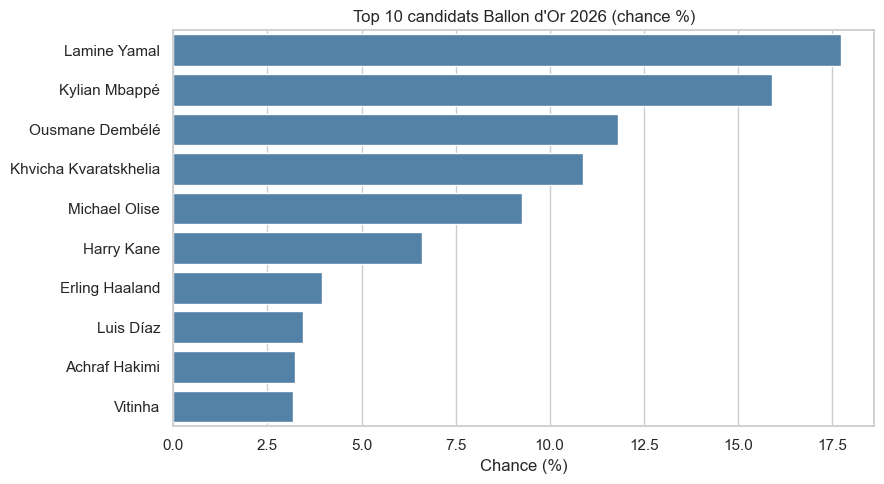

In [27]:
# Graphique du Top 10
top10 = classement.head(10)
plt.figure(figsize=(9, 5))
sns.barplot(data=top10, y="joueur", x="chance_%", color="steelblue")
plt.title("Top 10 candidats Ballon d'Or 2026 (chance %)")
plt.xlabel("Chance (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## Comment le modèle choisit le gagnant ?

### 1. Le modèle donne une note à chaque joueur
Pour chaque candidat, le modèle regarde ses statistiques (buts, passes, titres, Ligue des Champions...).
Chaque statistique a une **importance** apprise pendant l'entraînement. Le modèle les combine en une **note** :

`note = importance1 × buts + importance2 × passes + importance3 × titres + ...`

Plus un joueur a de bonnes statistiques, plus sa note est haute.

### 2. La note devient une probabilité
La note est transformée en **probabilité**, un nombre entre 0 % et 100 %, grâce à la fonction **sigmoïde** :

| Note | Probabilité | Ce que ça veut dire |
|---|---|---|
| très basse | proche de 0 % | n'a aucune chance |
| moyenne | 50 % | autant de chances de gagner que de perdre |
| très haute | proche de 100 % | très probable |

### 3. Pourquoi les probabilités sont réparties entre plusieurs joueurs
Chaque année, **plusieurs candidats** ont d'excellentes statistiques, mais il n'y a **qu'un seul gagnant** sur une trentaine de candidats.
La probabilité se répartit donc entre les meilleurs joueurs, et personne n'écrase tous les autres.

> **Ce qui compte** : la probabilité d'un joueur sert à le **comparer aux autres candidats de la même année**.

### 4. Comment on décide qui est le gagnant (1) et qui ne l'est pas (0)
Comme il y a **un seul Ballon d'Or par année**, on utilise cette règle :

1. On calcule la probabilité de chaque candidat.
2. On les **classe** du plus haut au plus bas.
3. **Le 1er du classement = gagnant prédit (1)**, tous les autres = 0.

| Joueur | Probabilité | Classement | Décision |
|---|---|---|---|
| A | 0.31 | 1er | **1 (gagnant prédit)** |
| B | 0.22 | 2e | 0 |
| C | 0.15 | 3e | 0 |

Avec cette règle, il y a toujours **une prédiction et un vrai gagnant par édition**.
C'est pour cela que **Precision = Recall = F1 = Top-1** : ces métriques mesurent toutes la même chose, à savoir **le modèle a-t-il trouvé le bon gagnant ?**

### 5. Le pourcentage `chance_%`
Pour obtenir un pourcentage facile à lire, on calcule la **part de chaque joueur** dans l'ensemble des candidats :

`chance_% = 100 × probabilité du joueur / somme des probabilités de tous les candidats`

La somme de toutes les chances fait **100 %**. Plus la part d'un joueur est grande, plus il est favori par rapport aux autres.